In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load Titanic Dataset

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

# Create a backup of original dataset
original_df = df.copy()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Display first 5 rows
print("First 5 rows:")
display(df.head())

# Display last 5 rows
print("Last 5 rows:")
display(df.tail())

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types
print("\nData Types:")
print(df.dtypes)

# Dataset information
print("\nDataset Information:")
df.info()

First 5 rows:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Last 5 rows:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


Dataset Shape: (891, 15)

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Data Types:
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891

In [4]:
# Separate numerical and categorical columns

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_columns = df.select_dtypes(
    include=['object', 'bool', 'category']
).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

Numerical Columns:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical Columns:
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [5]:
# Statistical summary of numerical columns

print("Numerical Summary Statistics:")
display(df.describe())

# Statistical summary of categorical columns

print("Categorical Summary Statistics:")
display(df.describe(include='object'))

Numerical Summary Statistics:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Categorical Summary Statistics:


,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


In [6]:
# Count missing values in each column

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

# Calculate missing value percentage

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

display(missing_report)

Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


,Missing Values,Missing Percentage
survived,0,0.000000
pclass,0,0.000000
sex,0,0.000000
age,177,19.865320
sibsp,0,0.000000
parch,0,0.000000
fare,0,0.000000
embarked,2,0.224467
class,0,0.000000
who,0,0.000000


In [7]:
# Create a copy before modifying the dataset

cleaned_df = df.copy()

# Fill missing Age values using median

cleaned_df['age'] = cleaned_df['age'].fillna(
    cleaned_df['age'].median()
)

# Fill missing Embarked values using mode

cleaned_df['embarked'] = cleaned_df['embarked'].fillna(
    cleaned_df['embarked'].mode()[0]
)

# Fill missing Embark_town values using mode

cleaned_df['embark_town'] = cleaned_df['embark_town'].fillna(
    cleaned_df['embark_town'].mode()[0]
)

# Remove Deck column due to excessive missing values

cleaned_df.drop(columns=['deck'], inplace=True)

# Check missing values after cleaning

print("Missing Values After Cleaning:")
print(cleaned_df.isnull().sum())

print("\nUpdated Dataset Shape:", cleaned_df.shape)

Missing Values After Cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Updated Dataset Shape: (891, 14)


In [8]:
# Create a copy before modifying the dataset

cleaned_df = df.copy()

# Fill missing Age values using median

cleaned_df['age'] = cleaned_df['age'].fillna(
    cleaned_df['age'].median()
)

# Fill missing Embarked values using mode

cleaned_df['embarked'] = cleaned_df['embarked'].fillna(
    cleaned_df['embarked'].mode()[0]
)

# Fill missing Embark_town values using mode

cleaned_df['embark_town'] = cleaned_df['embark_town'].fillna(
    cleaned_df['embark_town'].mode()[0]
)

# Remove Deck column due to excessive missing values

cleaned_df.drop(columns=['deck'], inplace=True)

# Check missing values after cleaning

print("Missing Values After Cleaning:")
print(cleaned_df.isnull().sum())

print("\nUpdated Dataset Shape:", cleaned_df.shape)

Missing Values After Cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Updated Dataset Shape: (891, 14)


In [9]:
# Step 6: Check duplicate records

# Count duplicate rows
duplicate_count = cleaned_df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

# Display duplicate rows
print("\nDuplicate Records:")
display(cleaned_df[cleaned_df.duplicated()])

# Remove duplicate rows if any
cleaned_df = cleaned_df.drop_duplicates()

print("\nDataset Shape After Removing Duplicates:")
print(cleaned_df.shape)

Number of Duplicate Rows: 116

Duplicate Records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
47,1,3,female,28.0,0,0,7.7500,Q,Third,woman,False,Queenstown,yes,True
55,1,1,male,28.0,0,0,35.5000,S,First,man,True,Southampton,yes,True
76,0,3,male,28.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
77,0,3,male,28.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
87,0,3,male,28.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
870,0,3,male,26.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
877,0,3,male,19.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
878,0,3,male,28.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,Southampton,no,True



Dataset Shape After Removing Duplicates:
(775, 14)


In [10]:
# Check unique values in categorical columns

print("Unique values in Sex:")
print(cleaned_df['sex'].unique())

print("\nUnique values in Embarked:")
print(cleaned_df['embarked'].unique())

print("\nUnique values in Class:")
print(cleaned_df['class'].unique())

print("\nUnique values in Who:")
print(cleaned_df['who'].unique())

Unique values in Sex:
['male' 'female']

Unique values in Embarked:
['S' 'C' 'Q']

Unique values in Class:
['Third' 'First' 'Second']

Unique values in Who:
['man' 'woman' 'child']


In [11]:
# Summary statistics for numerical columns

print("Summary Statistics of Numerical Columns:")

display(cleaned_df.describe())

Summary Statistics of Numerical Columns:


,survived,pclass,age,sibsp,parch,fare
count,775.000000,775.000000,775.000000,775.000000,775.000000,775.000000
mean,0.412903,2.246452,29.581187,0.529032,0.420645,34.878403
std,0.492674,0.853574,13.766359,0.990326,0.840565,52.408474
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,21.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,28.000000,0.000000,0.000000,15.900000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,34.197900
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [12]:
# Frequency counts of categorical columns

print("Passenger Count by Gender:")
display(cleaned_df['sex'].value_counts())

print("\nPassenger Count by Class:")
display(cleaned_df['class'].value_counts())

print("\nPassenger Count by Embarked Location:")
display(cleaned_df['embarked'].value_counts())

Passenger Count by Gender:


,count
sex,
male,483
female,292



Passenger Count by Class:


,count
class,
Third,401
First,210
Second,164



Passenger Count by Embarked Location:


,count
embarked,
S,562
C,155
Q,58


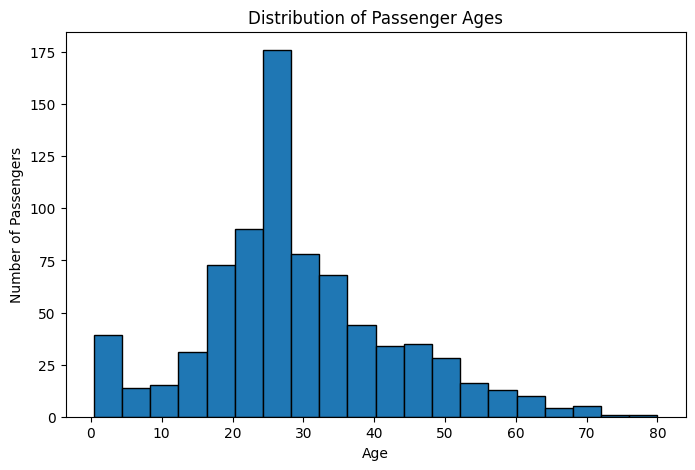

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(cleaned_df['age'], bins=20, edgecolor='black')

plt.title('Distribution of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

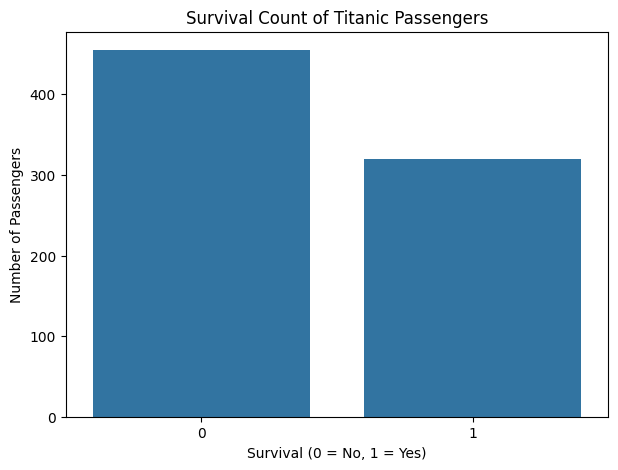

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(data=cleaned_df, x='survived')

plt.title('Survival Count of Titanic Passengers')
plt.xlabel('Survival (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

plt.show()

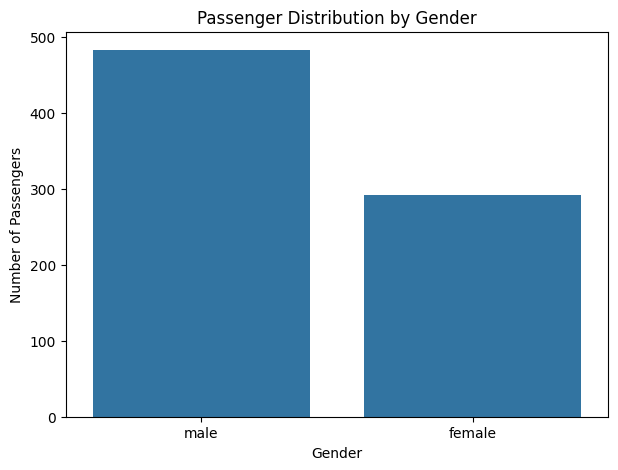

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(data=cleaned_df, x='sex')

plt.title('Passenger Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')

plt.show()

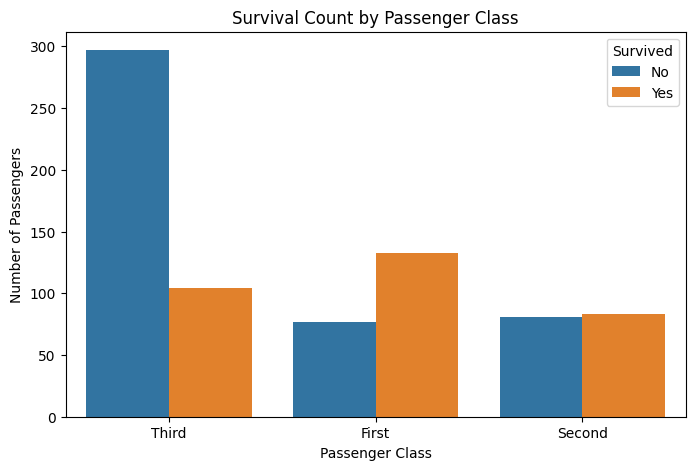

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=cleaned_df,
    x='class',
    hue='survived'
)

plt.title('Survival Count by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')

plt.legend(title='Survived', labels=['No', 'Yes'])

plt.show()

In [17]:
# Identify categorical columns

categorical_columns = cleaned_df.select_dtypes(
    include=['object', 'category', 'bool']
).columns

print("Categorical Columns:")
print(list(categorical_columns))

Categorical Columns:
['sex', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone']


In [18]:
# Create a copy for encoding

encoded_df = cleaned_df.copy()

# Apply One-Hot Encoding

encoded_df = pd.get_dummies(
    encoded_df,
    columns=['sex', 'embarked', 'who', 'embark_town'],
    dtype=int
)

print("Dataset After One-Hot Encoding:")
display(encoded_df.head())

print("\nUpdated Dataset Shape:", encoded_df.shape)


Dataset After One-Hot Encoding:


,survived,pclass,age,sibsp,parch,fare,class,adult_male,alive,alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
0,0,3,22.0,1,0,7.2500,Third,True,no,False,0,1,0,0,1,0,1,0,0,0,1
1,1,1,38.0,1,0,71.2833,First,False,yes,False,1,0,1,0,0,0,0,1,1,0,0
2,1,3,26.0,0,0,7.9250,Third,False,yes,True,1,0,0,0,1,0,0,1,0,0,1
3,1,1,35.0,1,0,53.1000,First,False,yes,False,1,0,0,0,1,0,0,1,0,0,1
4,0,3,35.0,0,0,8.0500,Third,True,no,True,0,1,0,0,1,0,1,0,0,0,1



Updated Dataset Shape: (775, 21)


In [19]:
from sklearn.preprocessing import StandardScaler

print("StandardScaler imported successfully!")

StandardScaler imported successfully!


In [20]:
# Create a copy of encoded dataset

scaled_df = encoded_df.copy()

# Select numerical features for scaling

features_to_scale = ['age', 'fare']

# Apply StandardScaler

scaler = StandardScaler()

scaled_df[features_to_scale] = scaler.fit_transform(
    scaled_df[features_to_scale]
)

print("Dataset After Feature Scaling:")
display(scaled_df.head())

print("\nScaled Feature Statistics:")
display(scaled_df[features_to_scale].describe())

Dataset After Feature Scaling:


,survived,pclass,age,sibsp,parch,fare,class,adult_male,alive,alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
0,0,3,-0.551060,1,0,-0.527515,Third,True,no,False,0,1,0,0,1,0,1,0,0,0,1
1,1,1,0.611945,1,0,0.695086,First,False,yes,False,1,0,1,0,0,0,0,1,1,0,0
2,1,3,-0.260308,0,0,-0.514627,Third,False,yes,True,1,0,0,0,1,0,0,1,0,0,1
3,1,1,0.393881,1,0,0.347909,First,False,yes,False,1,0,0,0,1,0,0,1,0,0,1
4,0,3,0.393881,0,0,-0.512240,Third,True,no,True,0,1,0,0,1,0,1,0,0,0,1



Scaled Feature Statistics:


,age,fare
count,7.750000e+02,7.750000e+02
mean,2.521281e-16,-1.134576e-16
std,1.000646e+00,1.000646e+00
min,-2.119661e+00,-6.659405e-01
25%,-6.237473e-01,-5.122402e-01
50%,-1.149330e-01,-3.623586e-01
75%,4.665691e-01,-1.299298e-02
max,3.664831e+00,9.116066e+00


In [21]:
# Check final dataset

print("Final Dataset Shape:", scaled_df.shape)

print("\nRemaining Missing Values:")
print(scaled_df.isnull().sum().sum())

print("\nRemaining Duplicate Rows:")
print(scaled_df.duplicated().sum())

print("\nFinal Dataset Preview:")
display(scaled_df.head())

Final Dataset Shape: (775, 21)

Remaining Missing Values:
0

Remaining Duplicate Rows:
0

Final Dataset Preview:


,survived,pclass,age,sibsp,parch,fare,class,adult_male,alive,alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
0,0,3,-0.551060,1,0,-0.527515,Third,True,no,False,0,1,0,0,1,0,1,0,0,0,1
1,1,1,0.611945,1,0,0.695086,First,False,yes,False,1,0,1,0,0,0,0,1,1,0,0
2,1,3,-0.260308,0,0,-0.514627,Third,False,yes,True,1,0,0,0,1,0,0,1,0,0,1
3,1,1,0.393881,1,0,0.347909,First,False,yes,False,1,0,0,0,1,0,0,1,0,0,1
4,0,3,0.393881,0,0,-0.512240,Third,True,no,True,0,1,0,0,1,0,1,0,0,0,1


In [22]:
# Save prepared dataset

scaled_df.to_csv(
    'Titanic_Prepared_Dataset.csv',
    index=False
)

print("Prepared dataset saved successfully!")

Prepared dataset saved successfully!


In [23]:
from google.colab import files

files.download('Titanic_Prepared_Dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
# Final Dataset Verification

print("FINAL DATASET REPORT")

print("\nDataset Shape:", scaled_df.shape)

print("\nTotal Missing Values:",
      scaled_df.isnull().sum().sum())

print("\nTotal Duplicate Rows:",
      scaled_df.duplicated().sum())

print("\nColumn Names:")
print(scaled_df.columns.tolist())

print("\nFinal Dataset Sample:")
display(scaled_df.head(10))

FINAL DATASET REPORT

Dataset Shape: (775, 21)

Total Missing Values: 0

Total Duplicate Rows: 0

Column Names:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'class', 'adult_male', 'alive', 'alone', 'sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S', 'who_child', 'who_man', 'who_woman', 'embark_town_Cherbourg', 'embark_town_Queenstown', 'embark_town_Southampton']

Final Dataset Sample:


,survived,pclass,age,sibsp,parch,fare,class,adult_male,alive,alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
0,0,3,-0.551060,1,0,-0.527515,Third,True,no,False,0,1,0,0,1,0,1,0,0,0,1
1,1,1,0.611945,1,0,0.695086,First,False,yes,False,1,0,1,0,0,0,0,1,1,0,0
2,1,3,-0.260308,0,0,-0.514627,Third,False,yes,True,1,0,0,0,1,0,0,1,0,0,1
3,1,1,0.393881,1,0,0.347909,First,False,yes,False,1,0,0,0,1,0,0,1,0,0,1
4,0,3,0.393881,0,0,-0.512240,Third,True,no,True,0,1,0,0,1,0,1,0,0,0,1
5,0,3,-0.114933,0,0,-0.504444,Third,True,no,True,0,1,0,1,0,0,1,0,0,1,0
6,0,1,1.774949,0,0,0.324281,First,True,no,True,0,1,0,0,1,0,1,0,0,0,1
7,0,3,-2.004815,3,1,-0.263551,Third,False,no,False,0,1,0,0,1,1,0,0,0,0,1
8,1,3,-0.187621,0,2,-0.453370,Third,False,yes,False,1,0,0,0,1,0,0,1,0,0,1
9,1,2,-1.132562,1,0,-0.091793,Second,False,yes,False,1,0,1,0,0,1,0,0,1,0,0


In [25]:
# Save original dataset
original_df.to_csv(
    'Titanic_Original_Dataset.csv',
    index=False
)

# Save final prepared dataset
scaled_df.to_csv(
    'Titanic_Prepared_Dataset.csv',
    index=False
)

print("Both datasets saved successfully!")

Both datasets saved successfully!


In [26]:
from google.colab import files

files.download('Titanic_Original_Dataset.csv')

files.download('Titanic_Prepared_Dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
print("FINAL PROJECT VERIFICATION")

print("Original Dataset Shape:", original_df.shape)
print("Prepared Dataset Shape:", scaled_df.shape)

print("Missing Values:", scaled_df.isnull().sum().sum())
print("Duplicate Rows:", scaled_df.duplicated().sum())

print("\nFinal Dataset:")
display(scaled_df.head())

FINAL PROJECT VERIFICATION
Original Dataset Shape: (891, 15)
Prepared Dataset Shape: (775, 21)
Missing Values: 0
Duplicate Rows: 0

Final Dataset:


,survived,pclass,age,sibsp,parch,fare,class,adult_male,alive,alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
0,0,3,-0.551060,1,0,-0.527515,Third,True,no,False,0,1,0,0,1,0,1,0,0,0,1
1,1,1,0.611945,1,0,0.695086,First,False,yes,False,1,0,1,0,0,0,0,1,1,0,0
2,1,3,-0.260308,0,0,-0.514627,Third,False,yes,True,1,0,0,0,1,0,0,1,0,0,1
3,1,1,0.393881,1,0,0.347909,First,False,yes,False,1,0,0,0,1,0,0,1,0,0,1
4,0,3,0.393881,0,0,-0.512240,Third,True,no,True,0,1,0,0,1,0,1,0,0,0,1


In [28]:
# Rebuild cleaned dataset from original data

cleaned_df = original_df.copy()

# Handle missing Age values
cleaned_df['age'] = cleaned_df['age'].fillna(
    cleaned_df['age'].median()
)

# Handle missing Embarked values
cleaned_df['embarked'] = cleaned_df['embarked'].fillna(
    cleaned_df['embarked'].mode()[0]
)

# Handle missing Embark_town values
cleaned_df['embark_town'] = cleaned_df['embark_town'].fillna(
    cleaned_df['embark_town'].mode()[0]
)

# Remove Deck column
cleaned_df.drop(columns=['deck'], inplace=True)

print("Corrected Dataset Shape:", cleaned_df.shape)
print("Missing Values:", cleaned_df.isnull().sum().sum())

Corrected Dataset Shape: (891, 14)
Missing Values: 0


In [29]:
# One-hot encoding

encoded_df = pd.get_dummies(
    cleaned_df,
    columns=['sex', 'embarked', 'who', 'embark_town'],
    dtype=int
)

# Feature scaling

from sklearn.preprocessing import StandardScaler

scaled_df = encoded_df.copy()

scaler = StandardScaler()

features_to_scale = ['age', 'fare']

scaled_df[features_to_scale] = scaler.fit_transform(
    scaled_df[features_to_scale]
)

print("Final Dataset Shape:", scaled_df.shape)
display(scaled_df.head())

Final Dataset Shape: (891, 21)


,survived,pclass,age,sibsp,parch,fare,class,adult_male,alive,alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
0,0,3,-0.565736,1,0,-0.502445,Third,True,no,False,0,1,0,0,1,0,1,0,0,0,1
1,1,1,0.663861,1,0,0.786845,First,False,yes,False,1,0,1,0,0,0,0,1,1,0,0
2,1,3,-0.258337,0,0,-0.488854,Third,False,yes,True,1,0,0,0,1,0,0,1,0,0,1
3,1,1,0.433312,1,0,0.420730,First,False,yes,False,1,0,0,0,1,0,0,1,0,0,1
4,0,3,0.433312,0,0,-0.486337,Third,True,no,True,0,1,0,0,1,0,1,0,0,0,1


In [30]:
scaled_df.to_csv(
    'Titanic_Prepared_Dataset.csv',
    index=False
)

print("Corrected prepared dataset saved!")

Corrected prepared dataset saved!


In [31]:
from google.colab import files

files.download('Titanic_Prepared_Dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
print("FINAL PROJECT VERIFICATION")

print("Original Dataset:", original_df.shape)
print("Prepared Dataset:", scaled_df.shape)

print("Missing Values:", scaled_df.isnull().sum().sum())
print("Duplicate Rows:", scaled_df.duplicated().sum())

display(scaled_df.head())

FINAL PROJECT VERIFICATION
Original Dataset: (891, 15)
Prepared Dataset: (891, 21)
Missing Values: 0
Duplicate Rows: 116


,survived,pclass,age,sibsp,parch,fare,class,adult_male,alive,alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
0,0,3,-0.565736,1,0,-0.502445,Third,True,no,False,0,1,0,0,1,0,1,0,0,0,1
1,1,1,0.663861,1,0,0.786845,First,False,yes,False,1,0,1,0,0,0,0,1,1,0,0
2,1,3,-0.258337,0,0,-0.488854,Third,False,yes,True,1,0,0,0,1,0,0,1,0,0,1
3,1,1,0.433312,1,0,0.420730,First,False,yes,False,1,0,0,0,1,0,0,1,0,0,1
4,0,3,0.433312,0,0,-0.486337,Third,True,no,True,0,1,0,0,1,0,1,0,0,0,1


In [33]:
# Inspect duplicate records

duplicate_records = scaled_df[
    scaled_df.duplicated(keep=False)
]

print("Total duplicate-related records:",
      len(duplicate_records))

display(duplicate_records.head(10))

Total duplicate-related records: 174


,survived,pclass,age,sibsp,parch,fare,class,adult_male,alive,alone,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
4,0,3,0.433312,0,0,-0.486337,Third,True,no,True,0,1,0,0,1,0,1,0,0,0,1
23,1,1,-0.104637,0,0,0.066360,First,True,yes,True,0,1,0,0,1,0,1,0,0,0,1
26,0,3,-0.104637,0,0,-0.502949,Third,True,no,True,0,1,1,0,0,0,1,0,1,0,0
28,1,3,-0.104637,0,0,-0.489776,Third,False,yes,True,1,0,0,1,0,0,0,1,0,1,0
29,0,3,-0.104637,0,0,-0.489442,Third,True,no,True,0,1,0,0,1,0,1,0,0,0,1
32,1,3,-0.104637,0,0,-0.492378,Third,False,yes,True,1,0,0,1,0,0,0,1,0,1,0
37,0,3,-0.642586,0,0,-0.486337,Third,True,no,True,0,1,0,0,1,0,1,0,0,0,1
42,0,3,-0.104637,0,0,-0.489442,Third,True,no,True,0,1,1,0,0,0,1,0,1,0,0
45,0,3,-0.104637,0,0,-0.486337,Third,True,no,True,0,1,0,0,1,0,1,0,0,0,1
46,0,3,-0.104637,1,0,-0.336334,Third,True,no,False,0,1,0,1,0,0,1,0,0,1,0
